In [5]:
'''   
Straight Line Concept is used-
--------------------------------
y = mx + c

y= predicted data
m= slope
x= data points
c= intercepts (constant)

- Linear Regression is sensitive to Outliers

Metrices
-------------------------------------------------
- Target Test Data ( x-axis) and Predicted Data( y-axis)

- MAE ( Mean Absolute Error)
   -> sum of distance between best fit line and data points

- MSE ( Mean Squared Error)
   -> sum of square between best fit line and data points

- RMSE ( Root Mean Squared Error)
    -> square root of MSE

- R2 Score ( Resudiual Score)

If RMSE decreses then R2 Score increases ( Correct )
If RMSE increases then R2 Score decreases


'''

'   \nStraight Line Concept is used-\n--------------------------------\ny = mx + c\n\ny= predicted data\nm= slope\nx= data points\nc= intercepts (constant)\n\n- Linear Regression is sensitive to Outliers\n\nMetrices\n-------------------------------------------------\n- Target Test Data ( x-axis) and Predicted Data( y-axis)\n\n- MAE ( Mean Absolute Error)\n   -> sum of distance between best fit line and data points\n\n- MSE ( Mean Squared Error)\n   -> sum of square between best fit line and data points\n\n- RMSE ( Root Mean Squared Error)\n    -> square root of MSE\n\n- R2 Score ( Resudiual Score)\n\nIf RMSE decreses then R2 Score increases ( Correct )\nIf RMSE increases then R2 Score decreases\n\n\n'

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# import model
from sklearn.linear_model import LinearRegression

# for splitting
from sklearn.model_selection import train_test_split

# for scaling of data
from sklearn.preprocessing import StandardScaler

# import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df =pd.read_csv('Dataset/Real estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [3]:
''''   
determining features and target then after removing columns that have no use
like in this case [No] and [Trasaction date]

'''

"'   \ndetermining features and target then after removing columns that have no use\nlike in this case [No] and [Trasaction date]\n\n"

### Data Wragling

In [4]:
df.columns


Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [6]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [7]:
df= df.drop(columns=['No', 'X1 transaction date',])

In [8]:
df.head()

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1


<Axes: ylabel='X6 longitude'>

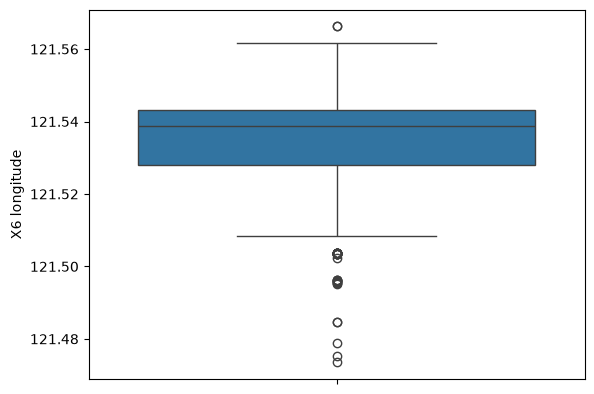

In [9]:
# observing outliers in each column using boxplot
# circle represents outliers


# sns.boxplot(df['X2 house age'])    -- no outliers
# sns.boxplot(df['X3 distance to the nearest MRT station'])   --contains outliers
# sns.boxplot(df['X4 number of convenience stores'])          -- no outliers
# sns.boxplot(df['X5 latitude'])       -- some outliers
sns.boxplot(df['X6 longitude'])     # <= 121 and >= 121.50 for removing outliers    # -- contains outliers


<Axes: ylabel='X5 latitude'>

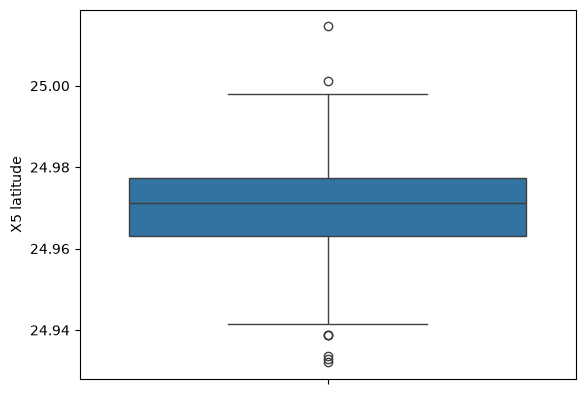

In [10]:
sns.boxplot(df['X5 latitude'])     # less then 25 and more then 24

<Axes: ylabel='X3 distance to the nearest MRT station'>

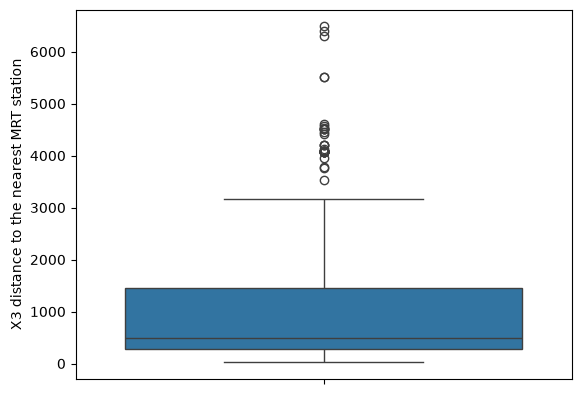

In [11]:
sns.boxplot(df['X3 distance to the nearest MRT station'])    # less then 3200

### Using IQR (Inter Quartial Range) to clean data

In [12]:
df['X3 distance to the nearest MRT station']

0        84.87882
1       306.59470
2       561.98450
3       561.98450
4       390.56840
          ...    
409    4082.01500
410      90.45606
411     390.96960
412     104.81010
413      90.45606
Name: X3 distance to the nearest MRT station, Length: 414, dtype: float64

In [13]:
# Q1 -> 0.25
# Q2 -> 0.5
# Q3 -> 0.75

df['X3 distance to the nearest MRT station']

In [14]:
q1 = df['X3 distance to the nearest MRT station'].quantile(0.25)
q3 = df['X3 distance to the nearest MRT station'].quantile(0.75)


In [15]:
iqr= q3-q1


In [16]:
distance_lower_bound= q1-(1.5 *iqr)
distance_upper_bound= q3+(1.5 *iqr)

distance_lower_bound

np.float64(-1458.1065000000003)

In [17]:
df= df[df['X3 distance to the nearest MRT station'].between(distance_lower_bound,distance_upper_bound)]
df

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
408,18.5,2175.74400,3,24.96330,121.51243,28.1
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


<Axes: ylabel='X3 distance to the nearest MRT station'>

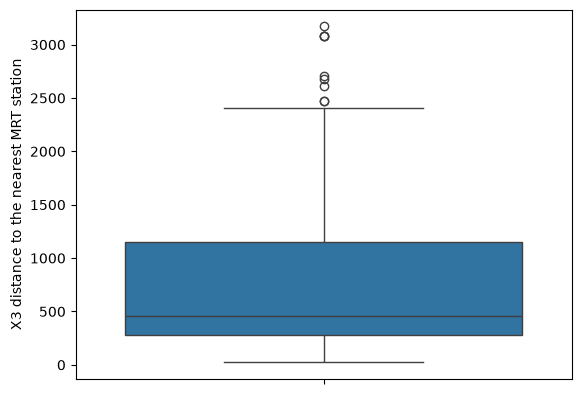

In [18]:
sns.boxplot(df['X3 distance to the nearest MRT station'])

df['X5 latitude']

In [19]:
q1 = df['X5 latitude'].quantile(0.25)
q3 = df['X5 latitude'].quantile(0.75)

iqr= q3-q1

lat_lower_bound= q1-(1.5 *iqr)
lat_upper_bound= q3+(1.5 *iqr)

In [20]:
df= df[df['X5 latitude'].between(lat_lower_bound,lat_upper_bound)]

<Axes: ylabel='X5 latitude'>

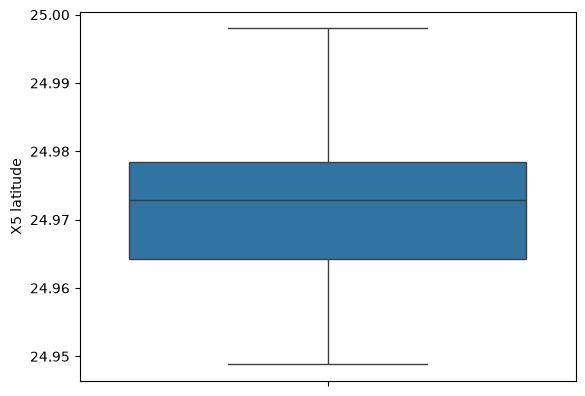

In [21]:
sns.boxplot(df['X5 latitude'])

df['X5 longitude']

In [22]:
q1 = df['X6 longitude'].quantile(0.25)
q3 = df['X6 longitude'].quantile(0.75)

iqr= q3-q1

lon_lower_bound= q1-(1.5 *iqr)
lon_upper_bound= q3+(1.5 *iqr)

In [23]:
lon_lower_bound

np.float64(121.51862374999999)

In [24]:
df= df[df['X6 longitude'].between(lon_lower_bound,lon_upper_bound)]

In [25]:
df

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
406,1.9,372.13860,7,24.97293,121.54026,40.5
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


<Axes: ylabel='X6 longitude'>

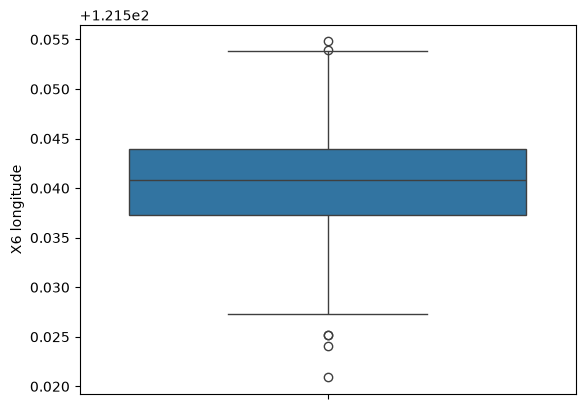

In [26]:
sns.boxplot(df['X6 longitude'])

In [27]:
# # filtering (outliers)

# # another data frame
# filter_data= df[
#     (df['X3 distance to the nearest MRT station']<3100)
#     & (df['X5 latitude'].between(24,25))
#     & (df['X6 longitude']> 121.50)
# ]
# filter_data

In [28]:
filter_data.columns

NameError: name 'filter_data' is not defined

In [17]:
df


,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
409,13.7,4082.01500,0,24.94155,121.50381,15.4
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


In [18]:
# out of 414 rows we filteres upto 376 rows

###  Separate Feature and Target

In [29]:
features= ['X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']

target='Y house price of unit area'

In [30]:
X= df[features]
Y= df[target]

In [31]:
X

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,32.0,84.87882,10,24.98298,121.54024
1,19.5,306.59470,9,24.98034,121.53951
2,13.3,561.98450,5,24.98746,121.54391
3,13.3,561.98450,5,24.98746,121.54391
4,5.0,390.56840,5,24.97937,121.54245
...,...,...,...,...,...
406,1.9,372.13860,7,24.97293,121.54026
410,5.6,90.45606,9,24.97433,121.54310
411,18.8,390.96960,7,24.97923,121.53986
412,8.1,104.81010,5,24.96674,121.54067


In [32]:
Y

0      37.9
1      42.2
2      47.3
3      54.8
4      43.1
       ... 
406    40.5
410    50.0
411    40.6
412    52.5
413    63.9
Name: Y house price of unit area, Length: 315, dtype: float64

### Train Test Split

In [33]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.2, random_state =42
)

### Feature Scaling

In [ ]:
'''   
-> (Xi -mean)/ sd

- fit_transform(X_train) -> ( fit -> learning ( mean and sd) , transform -> implement)
- transform(X_test) -> [ transforms -> implement]


'''

'   \n-> (Xi -mean)/ sd\n\n- fit_transform(X_train) -> ( fit -> learning ( mean and sd) , transform -> implement)\n- transform(Y-train) -> [ transforms -> implement]\n\n\n'

In [34]:
scaler= StandardScaler()
X_train_scale= scaler.fit_transform(X_train)
X_test_scale= scaler.transform(X_test)

### Define Model

In [ ]:
model= LinearRegression()


In [36]:
# fit learning data to model

# model.fit( feature-> X_train_scale, target-> Y_train)

# features and targets are used as arguments in function with which model is trained 

model.fit(X_train_scale, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[-3.55,-4.94, 1.03, 3.25, 0.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,42.39
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[20.86,17.52,15.74,13.82, 8.91]"


In [37]:
# Now the above trained model is tested with testing record

Y_pred = model.predict(X_test_scale)

### Metrics

In [38]:
beta_0= model.intercept_
beta_1= model.coef_

print(f'Intercept: {beta_0}')
print(f'Slope: {beta_1}')

Intercept: 42.38888888888955
Slope: [-3.54903269 -4.93596231  1.02653205  3.24807193  0.1193727 ]


In [ ]:
# metircs( Y_test (actual data), Y_pred( predicted data))

mae= mean_absolute_error(Y_test,Y_pred)
mse= mean_squared_error(Y_test,Y_pred)
rmse= np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)





In [40]:
print(f'Mean Absolute Error: {mae:,.2f}')
print(f'Mean Squared Error: {mse:,.2f}')
print(f'Root Mean Squared Error: {rmse:,.2f}')
print(f'R2 Score: {r2:,.2f}')

Mean Absolute Error: 6.20
Mean Squared Error: 76.88
Root Mean Squared Error: 8.77
R2 Score: 0.53


### Visualization

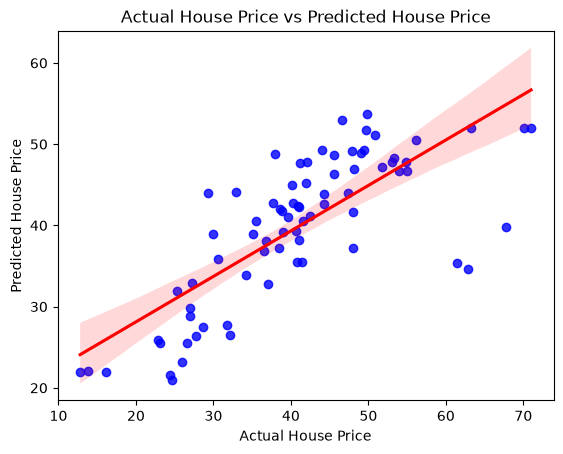

In [38]:
sns.regplot(x= Y_test, y = Y_pred, color= 'blue', line_kws={'color':'red'})
plt.xlabel('Actual House Price')
plt.ylabel('Predicted House Price')
plt.title('Actual House Price vs Predicted House Price')
plt.show()

In [ ]:
'''   
Sometimes outliers are also important to make prediction


if we havenot removed the outliers mannually then we would have got more accuracy.
 with removed outlier(accuracy) : 0.58
 without removing outlier( accuracy) : 0.67


overall... Other model should be used 



'''

### Random Forest

In [41]:
from sklearn.ensemble import RandomForestRegressor

In [42]:
rf_model= RandomForestRegressor()

In [43]:
rf_model.fit(X_train_scale, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [44]:
rf_pred= rf_model.predict(X_test_scale)

In [45]:
rf_mae= mean_absolute_error(Y_test, rf_pred)
rf_mse= mean_squared_error(Y_test, rf_pred)
rf_rmse= np.sqrt(rf_mse)
rf_r2= r2_score(Y_test, rf_pred)

In [46]:
print(f'Mean Absolute Error: {rf_mae:,.2f}')
print(f'Mean Squared Error: {rf_mse:,.2f}')
print(f'Root Mean Squared Error: {rf_rmse:,.2f}')
print(f'R2 Score: {rf_r2:,.2f}')

Mean Absolute Error: 5.54
Mean Squared Error: 63.24
Root Mean Squared Error: 7.95
R2 Score: 0.61


<Axes: xlabel='Y house price of unit area'>

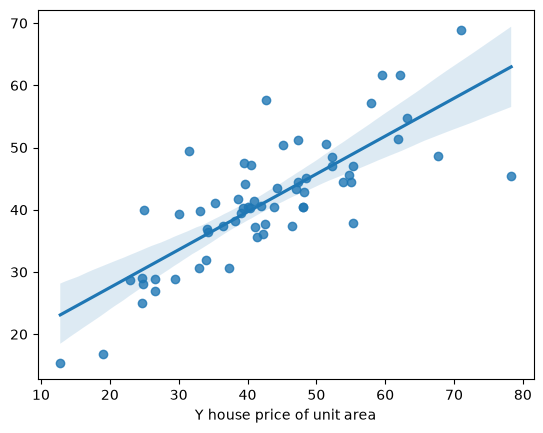

In [47]:
sns.regplot(x= Y_test, y=rf_pred)

In [ ]:
'''   
Types of regression Model Evaluation
-----------------------------------------
1.Cross Validation( Universal)
   - mostly used for saml or medium size datasets(<=100000)
   - Model will learn train data 5 to 6 times

2. Polynomial Regression
   - If our feature contains any non-linear pattern
   - Handles non linear pattern.

3. Ridge Regression
   - COnverts high weight features to 0 or class to zero

4. Lasso Regression
   - Removes high weight features

5. Elastic Net
   - Hybrid Regresssion -> Combination of RIdge Regression and Lasso Regression


6. Adjusting R2 Score
    -> 1-((1-r2)*(n-1))/(n-p-1)

    n- number of samples  (X_test_scale.shape[0])
    p-population  (X_train_scale.shape[1])
'''

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# import LInear, Ridge, Lasso, Elastic Net
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# for splitting feature and target and cross validation
from sklearn.model_selection import train_test_split,KFold, cross_val_score

# for scaling of data and polynomial regresssion
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

# import metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# import Pipeline
from sklearn.pipeline import Pipeline

In [11]:
df= pd.read_csv('Dataset/Real estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [30]:
# Since Adjusting R2 score is used for all types of regression evaluation so creating function

def adjust_r2_score(r2,n,p):
    return 1-((1-r2)*(n-1))/(n-p-1)

In [31]:
# spliting feature and target

features= ['X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']

target='Y house price of unit area'


# initializing feature and target to new X and Y variable
X= df[features]
Y= df[target]


# splitting data to training and testing
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size= 0.2, random_state =42
)

In [32]:
# feature Scaling
scaler= StandardScaler()
X_train_scale= scaler.fit_transform(X_train)
X_test_scale= scaler.transform(X_test)

In [33]:
#define model

model= LinearRegression()
model.fit(X_train_scale, Y_train)
Y_pred = model.predict(X_test_scale)

In [34]:
n_samples=X_test_scale.shape[0]
p=X_train_scale.shape[1]

p

5

In [35]:
mae= mean_absolute_error(Y_test,Y_pred)
mse= mean_squared_error(Y_test,Y_pred)
rmse= np.sqrt(mse)
r2=r2_score(Y_test,Y_pred)
adjust_r2= adjust_r2_score(r2,n_samples,p)


print(f'Mean Absolute Error: {mae:,.2f}')
print(f'Mean Squared Error: {mse:,.2f}')
print(f'Root Mean Squared Error: {rmse:,.2f}')
print(f'R2 Score: {r2:,.2f}')
print(f'Adjusted R2 Score: {adjust_r2}')

Mean Absolute Error: 5.35
Mean Squared Error: 54.58
Root Mean Squared Error: 7.39
R2 Score: 0.67
Adjusted R2 Score: 0.653521394015468


Cross Validation of Data

In [ ]:
kf= KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores= cross_val_score(model, scaler.fit_transform(X),Y, scoring='r2')

print(f'Cross Validation Score: {cv_scores}')       # accuracy of 5 splited datas
print(f'Average of Cross Validation Score: {cv_scores.mean()}')


Cross Validation Score: [0.68463546 0.53209757 0.66649314 0.42112676 0.57912236]
Average of Cross Validation Score: 0.5766950593066443


Polynomial Regression

In [46]:
# pipeline contains data scaling, identify non-linear pattern and then linear regression

poly_features= Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])


poly_features.fit(X_train_scale,Y_train)
poly_pred=poly_features.predict(X_test_scale)
poly_r2= r2_score(Y_test, poly_pred)
poly_adjusted_r2= adjust_r2_score(poly_r2,n_samples,p)


print(f'Polynomial Regression R2 Score: {poly_r2:,.2f}')
print(f'Polynomial Regression Adjusted R2 Score: {poly_adjusted_r2}')

Polynomial Regression R2 Score: 0.75
Polynomial Regression Adjusted R2 Score: 0.734334083777302


In [ ]:
'''   
alpha= 0.1,1,10,100

Ridge Regression standar alpha value= 1.0 ->l1
Lasso and Elastic Net Regressiom standard alpha value = 0.1 ->l2

'''

Ridge Regression

In [ ]:
# convert high weight features to near zero to match weight of low features data

ridge_pipeline= Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train_scale,Y_train)
ridge_pred=ridge_pipeline.predict(X_test_scale)
ridge_r2= r2_score(Y_test, ridge_pred)
ridge_adjusted_r2= adjust_r2_score(ridge_r2,n_samples,p)


print(f'Ridge Regression R2 Score: {ridge_r2:,.2f}')
print(f'Ridge Regression Adjusted R2 Score: {ridge_adjusted_r2}')

Ridge Regression R2 Score: 0.67
Ridge Regression Adjusted R2 Score: 0.6538049586101671


Lasso Regression

In [ ]:
#Removes high weight features 

lasso_pipeline= Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.1))
])

lasso_pipeline.fit(X_train_scale,Y_train)
lasso_pred=lasso_pipeline.predict(X_test_scale)
lasso_r2= r2_score(Y_test, lasso_pred)
lasso_adjusted_r2= adjust_r2_score(lasso_r2,n_samples,p)


print(f'Lasso Regression R2 Score: {lasso_r2:,.2f}')
print(f'Lasso Regression Adjusted R2 Score: {lasso_adjusted_r2:,.2f}')

Lasso Regression R2 Score: 0.68
Lasso Regression Adjusted R2 Score: 0.66


Elastic Net

In [ ]:
# if required high weighted features will be removed, if not required then high weight feature value will be minimized to zero

elastic_pipeline= Pipeline([
    ('scaler', StandardScaler()),
    ('elastic', ElasticNet(alpha=0.1, l1_ratio=0.5))
])

elastic_pipeline.fit(X_train_scale,Y_train)
elastic_pred=elastic_pipeline.predict(X_test_scale)
elastic_r2= r2_score(Y_test, elastic_pred)
elastic_adjusted_r2= adjust_r2_score(elastic_r2,n_samples,p)


print(f'Elastic Net Regression R2 Score: {elastic_r2:,.2f}')
print(f'Elastic Net Regression Adjusted R2 Score: {elastic_adjusted_r2:,.2f}')

Elastic Net Regression R2 Score: 0.68
Elastic Net Regression Adjusted R2 Score: 0.66


Visualization

<Axes: xlabel='Y house price of unit area'>

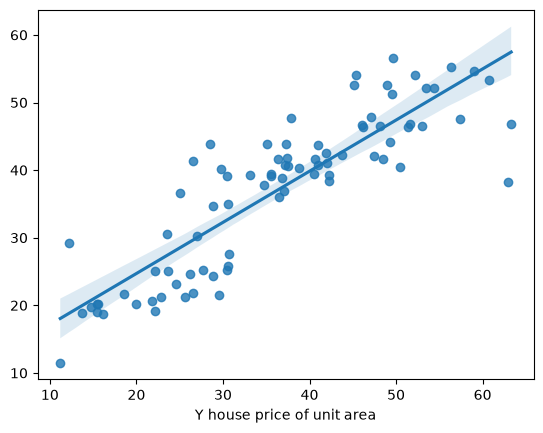

In [54]:
sns.regplot(x= Y_test, y= poly_pred)